# Stored Suggestion GP Diagnostics

Reconstruct the models trained through week 2 and plot each stored week-3 suggestion with its saved expected mean, standard deviation, and EI score. The historical candidate markers are compared with refitted models that exclude week-3 outcomes.

In [ ]:
%matplotlib inline
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

from bayesian_bbo import CONFIG, FUNCTION_SPECS
from bayesian_bbo.history import load_weekly_history
from bayesian_bbo.kernels import make_matern_32_kernel
from bayesian_bbo.optimisation import BayesianOptimizer, OptimisationConfig
from bayesian_bbo.visualisation import plot_gp_2d, plot_gp_slices

CURRENT_WEEK = 3
WEEK = 2
FUNCTION_IDS = tuple(FUNCTION_SPECS)

data_candidates = [Path("../../data"), Path("data"), Path("../data")]
matches = [path.resolve() for path in data_candidates if (path / "function_1").is_dir()]
if not matches:
    raise FileNotFoundError("Could not find the data directory from the notebook working directory.")
data_root: Path = matches[0]
history = load_weekly_history(data_root, current_week=CURRENT_WEEK, function_ids=FUNCTION_IDS)
TRAINING_OBSERVATIONS = {
    function_id: observations.through_week(WEEK)
    for function_id, observations in history.observations.items()
}
print(f"Data root: {data_root}")

Data root: /home/pabloncho/repositories/bayesian-bbo/data


## GP Mean, Uncertainty, and Expected Improvement

Use full-domain heatmaps for 2D inputs and coordinate slices through the stored candidate otherwise. Each slice shows the same candidate: the red triangle's horizontal position is that coordinate, and the dashed line marks the stored candidate input. Other coordinates stay fixed at the candidate. Slices show only observations whose other coordinates match the reference, not projections of off-slice observations. Often no training observations lie exactly on these slices.

The shaded band is the current model's pointwise mean +/- 1.96 predictive standard deviations, including the fitted WhiteKernel noise. Candidate coordinates come from `data/weekly_updates/week_{WEEK + 1}/inputs.json`; saved means, standard deviations, and EI scores come from `predictions.json`. Red triangles mark that stored candidate, not newly selected grid or slice maxima. Slice error bars show its saved mean +/- 1.96 std. Pass `expected_ei=stored_predictions["acquisition_scores"][function_id - 1]` to use the historical EI score. When `expected_mean`, `expected_std`, and `expected_ei` are all supplied, the helpers do not predict at the candidate again. Missing candidate values are predicted as a fallback. Heatmaps and slice curves still come from the current model. The true black-box function is unknown, so no true-function curve is drawn.

The stored-candidate example uses the Matérn 3/2 kernel and the configured length-scale caps. Its EI `xi` and incumbent `best` come from the saved `acquisition_settings`; UCB records are rejected rather than labelled as EI. `WEEK` is the last training week: training uses observations through week 2 and plots the stored week-3 suggestion, excluding its result. Normalization, optimizer restarts, and random seed use the same `fit_surrogate` defaults as the suggestion model. Saved predictions remain historical values and can differ from the refitted model. Change `plot_function_ids` to inspect another function. The separate live-suggestion example generates a new diagnostic candidate with the saved acquisition settings; it is not the stored week-3 candidate.

In [ ]:
LENGTH_CAPS = CONFIG["length_caps"]

In [ ]:
stored_rows = history.records.loc[history.records.week == WEEK + 1].set_index("function_id").loc[list(FUNCTION_IDS)]
if any(not isinstance(settings, dict) or settings.get("name") != "ei"
       for settings in stored_rows.acquisition_settings):
    raise ValueError("These EI diagnostics require saved EI scores, not UCB scores")
stored_inputs = stored_rows.candidate.tolist()
stored_predictions = {
    "expected_outputs": stored_rows.expected_mean.tolist(),
    "stds": stored_rows.expected_std.tolist(),
    "acquisition_scores": stored_rows.acquisition_score.tolist(),
    "acquisition_settings": stored_rows.acquisition_settings.tolist(),
}

In [4]:
pd.DataFrame({
    "function_id": FUNCTION_IDS,
    "suggested_point": stored_inputs,
    "expected_value": stored_predictions["expected_outputs"],
    "std": stored_predictions["stds"],
    "expected_ei": stored_predictions["acquisition_scores"],
})

,function_id,suggested_point,expected_value,std,expected_ei
0,1,"[0.55, 0.681526]",-0.003606,0.000006,0.000000
1,2,"[0.702637, 0.5]",0.604945,0.033011,0.003349
2,3,"[0.947062, 0.004655, 0.308533]",-0.013200,0.064582,0.018673
3,4,"[0.408628, 0.415278, 0.367734, 0.42364]",-1.054474,0.814679,0.120138
4,5,"[0.521778, 0.945288, 0.998122, 0.995876]",1608.846266,24.701896,2.016113
5,6,"[0.275981, 0.014585, 0.598845, 0.989524, 0.002...",-0.570396,0.316614,0.049801
6,7,"[0.004766, 0.024159, 0.641629, 0.165455, 0.346...",2.223120,0.185294,0.008189
7,8,"[0.031763, 0.022432, 0.081301, 0.006484, 0.954...",10.108850,0.215298,0.099918


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


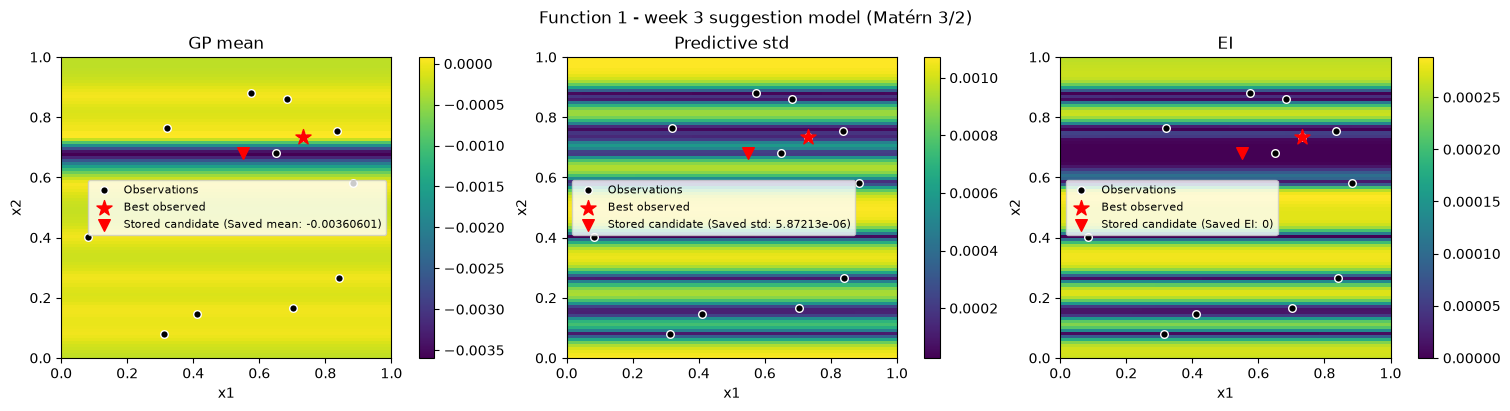

Function 1 - week 3 suggestion model kernel: 1.08**2 * Matern(length_scale=[31.6, 0.0377], nu=1.5) + WhiteKernel(noise_level=1e-08)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


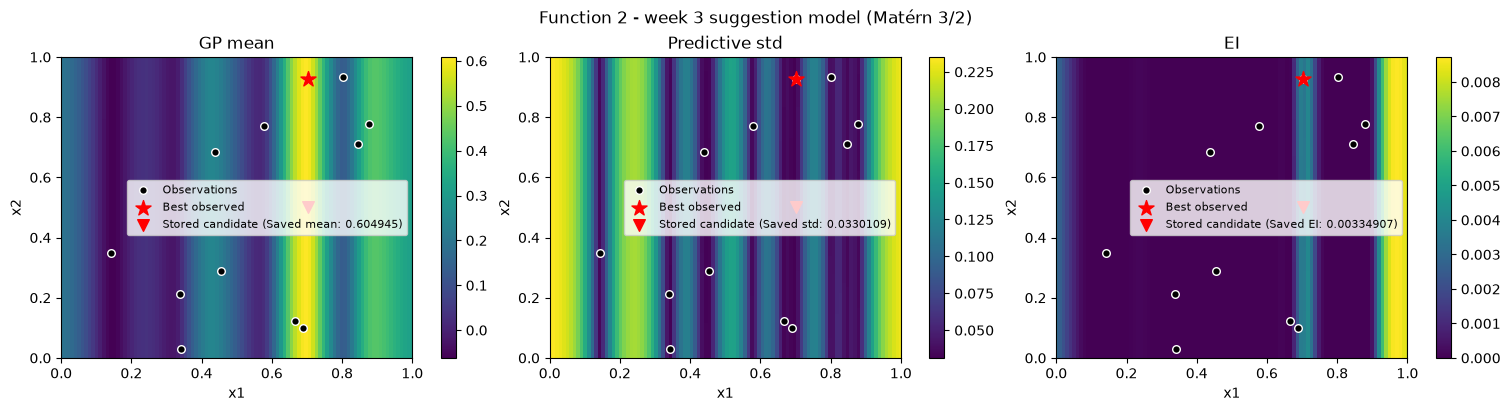

Function 2 - week 3 suggestion model kernel: 1.02**2 * Matern(length_scale=[0.0776, 31.6], nu=1.5) + WhiteKernel(noise_level=0.0107)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


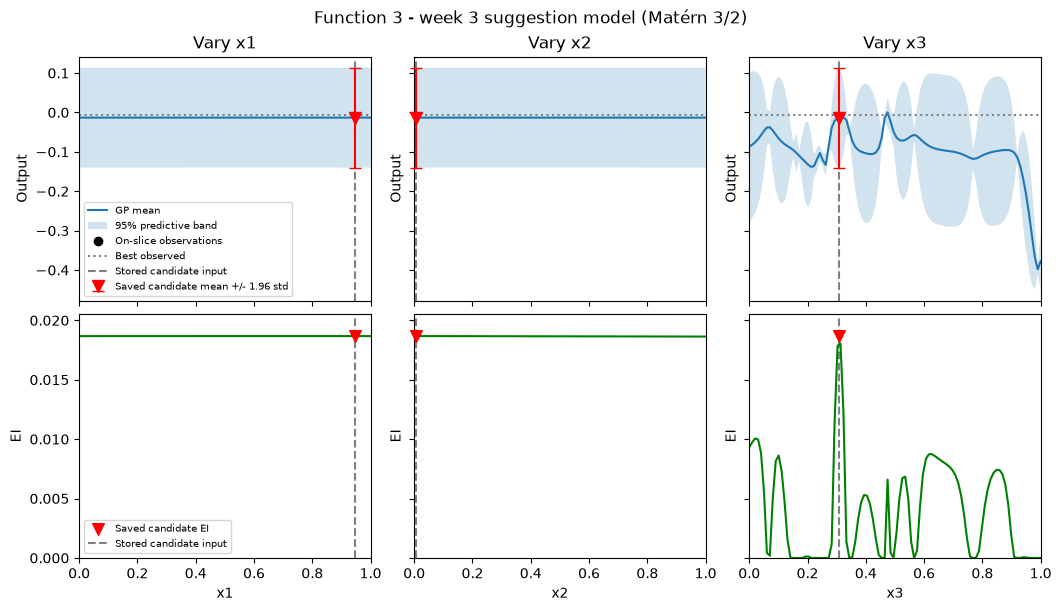

Function 3 - week 3 suggestion model kernel: 1.17**2 * Matern(length_scale=[31.6, 31.6, 0.036], nu=1.5) + WhiteKernel(noise_level=1e-06)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


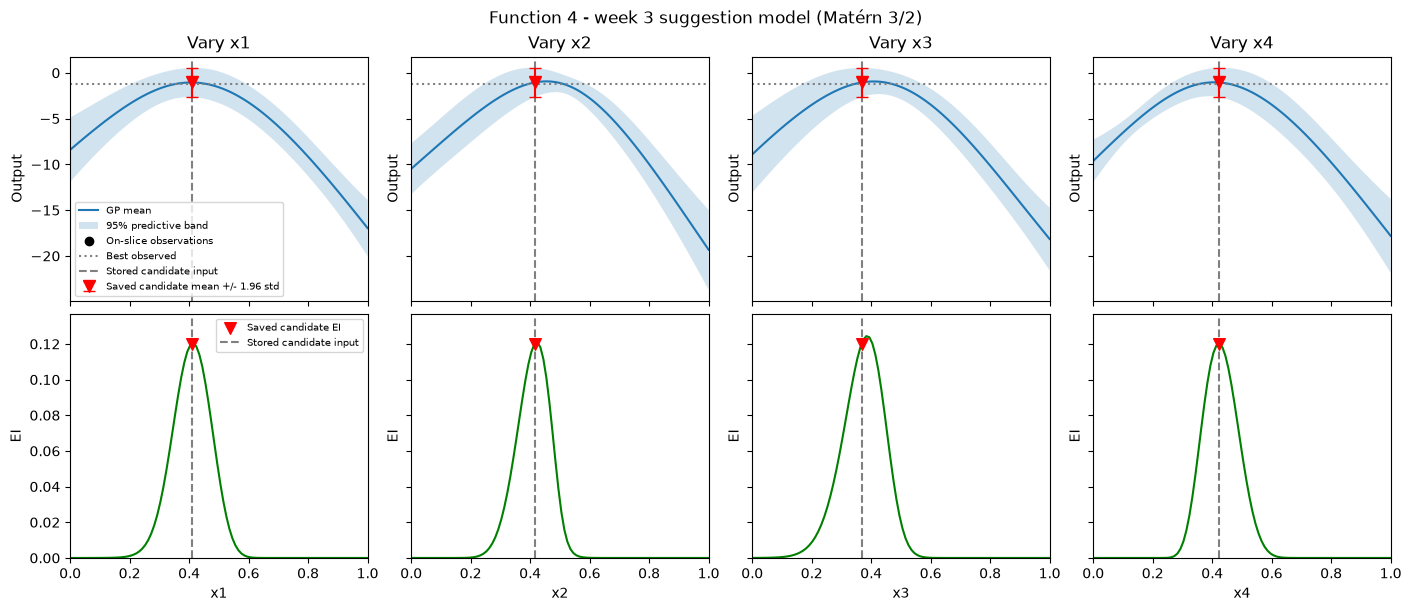

Function 4 - week 3 suggestion model kernel: 5.75**2 * Matern(length_scale=[3.99, 3.5, 3.83, 3.74], nu=1.5) + WhiteKernel(noise_level=1e-08)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


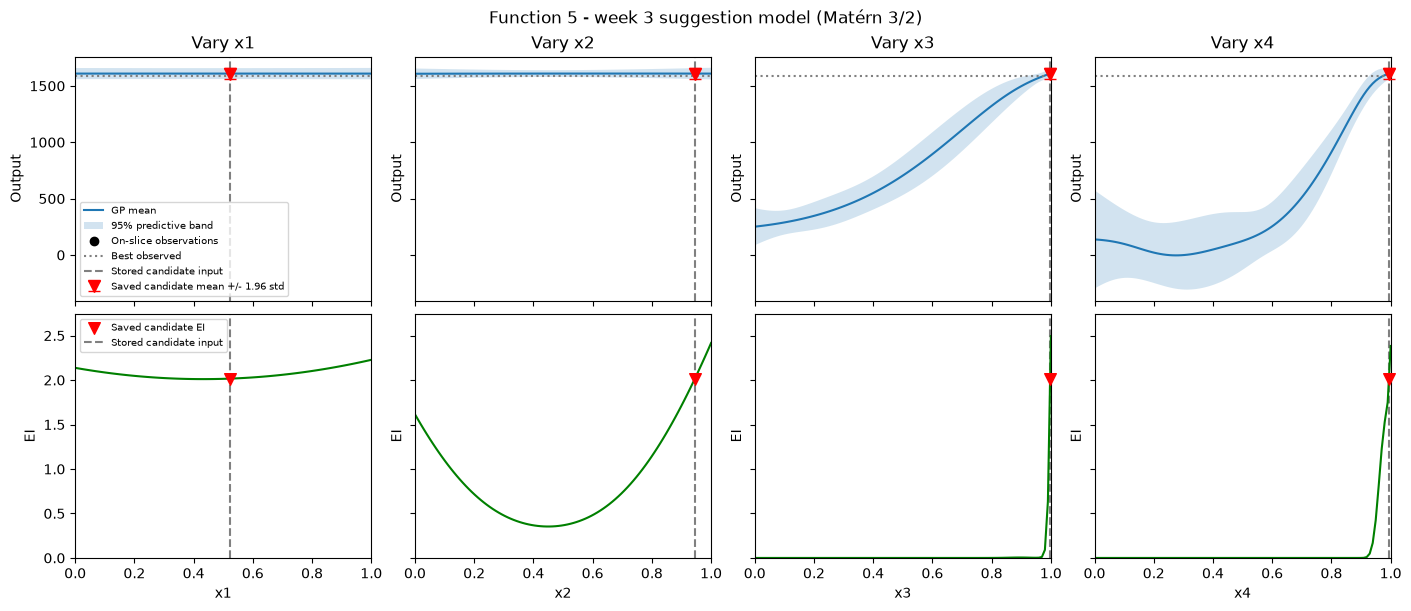

Function 5 - week 3 suggestion model kernel: 1.6**2 * Matern(length_scale=[100, 30.3, 1.37, 0.617], nu=1.5) + WhiteKernel(noise_level=1e-08)



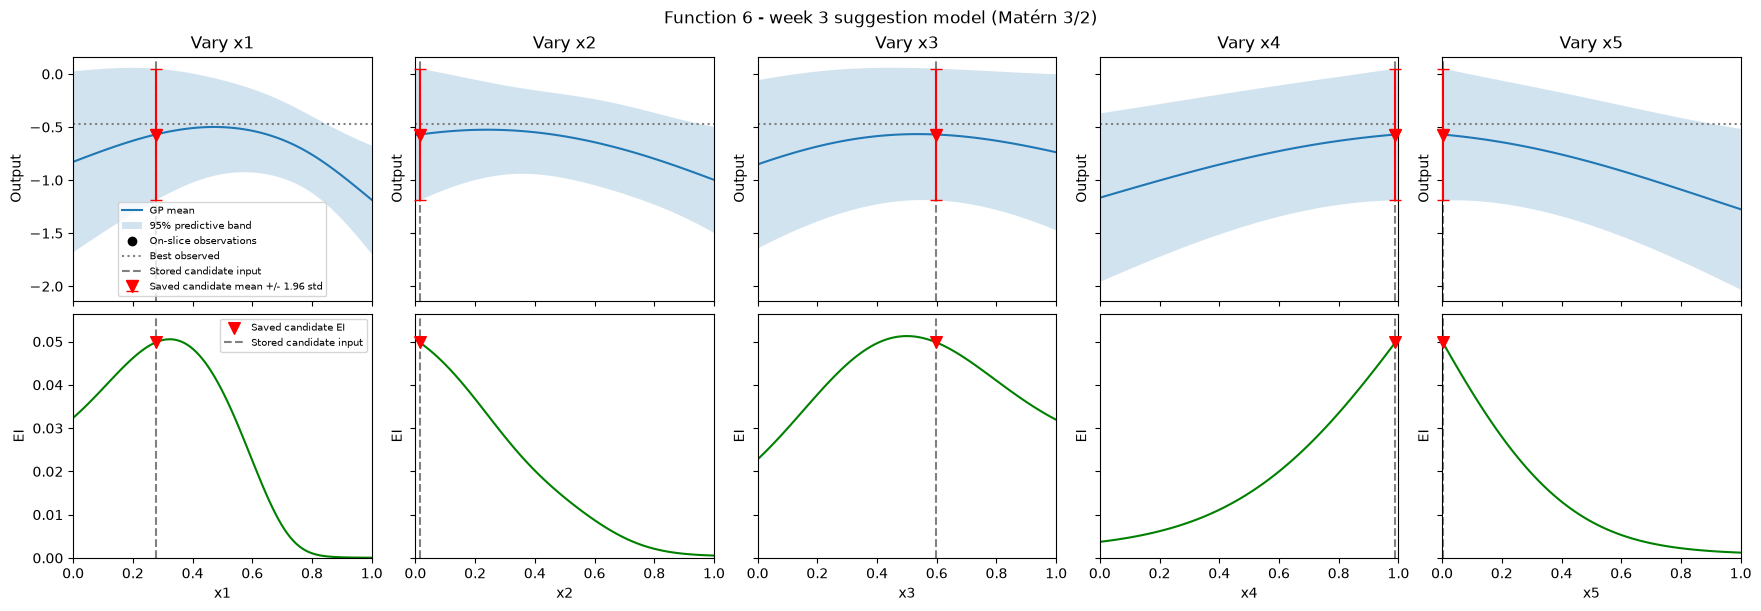

Function 6 - week 3 suggestion model kernel: 2.17**2 * Matern(length_scale=[1.22, 1.67, 1.75, 2.63, 2.19], nu=1.5) + WhiteKernel(noise_level=1e-05)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


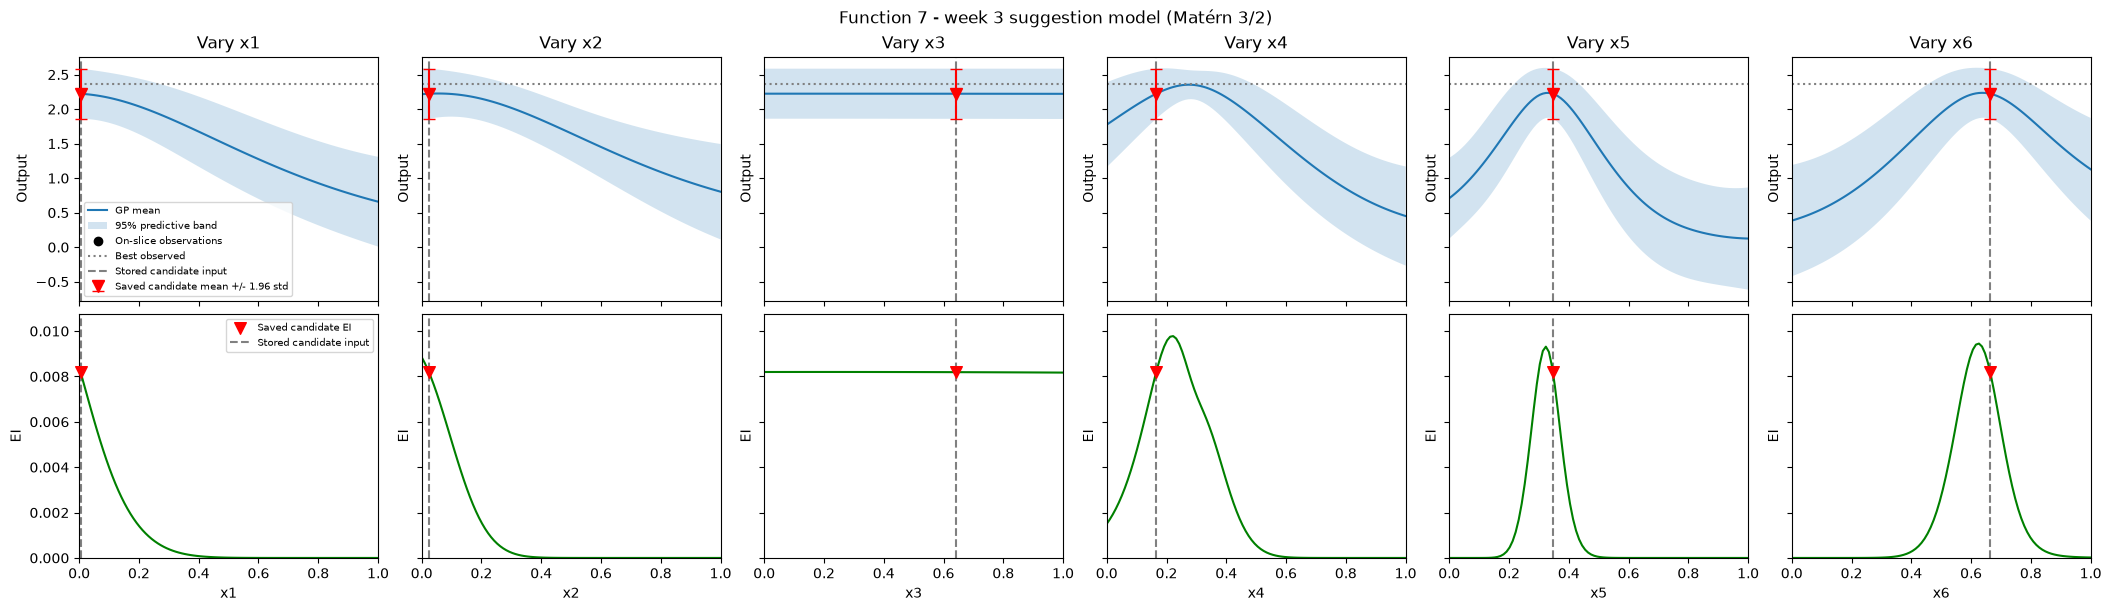

Function 7 - week 3 suggestion model kernel: 1.01**2 * Matern(length_scale=[0.868, 0.869, 31.6, 0.529, 0.265, 0.397], nu=1.5) + WhiteKernel(noise_level=9.98e-06)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


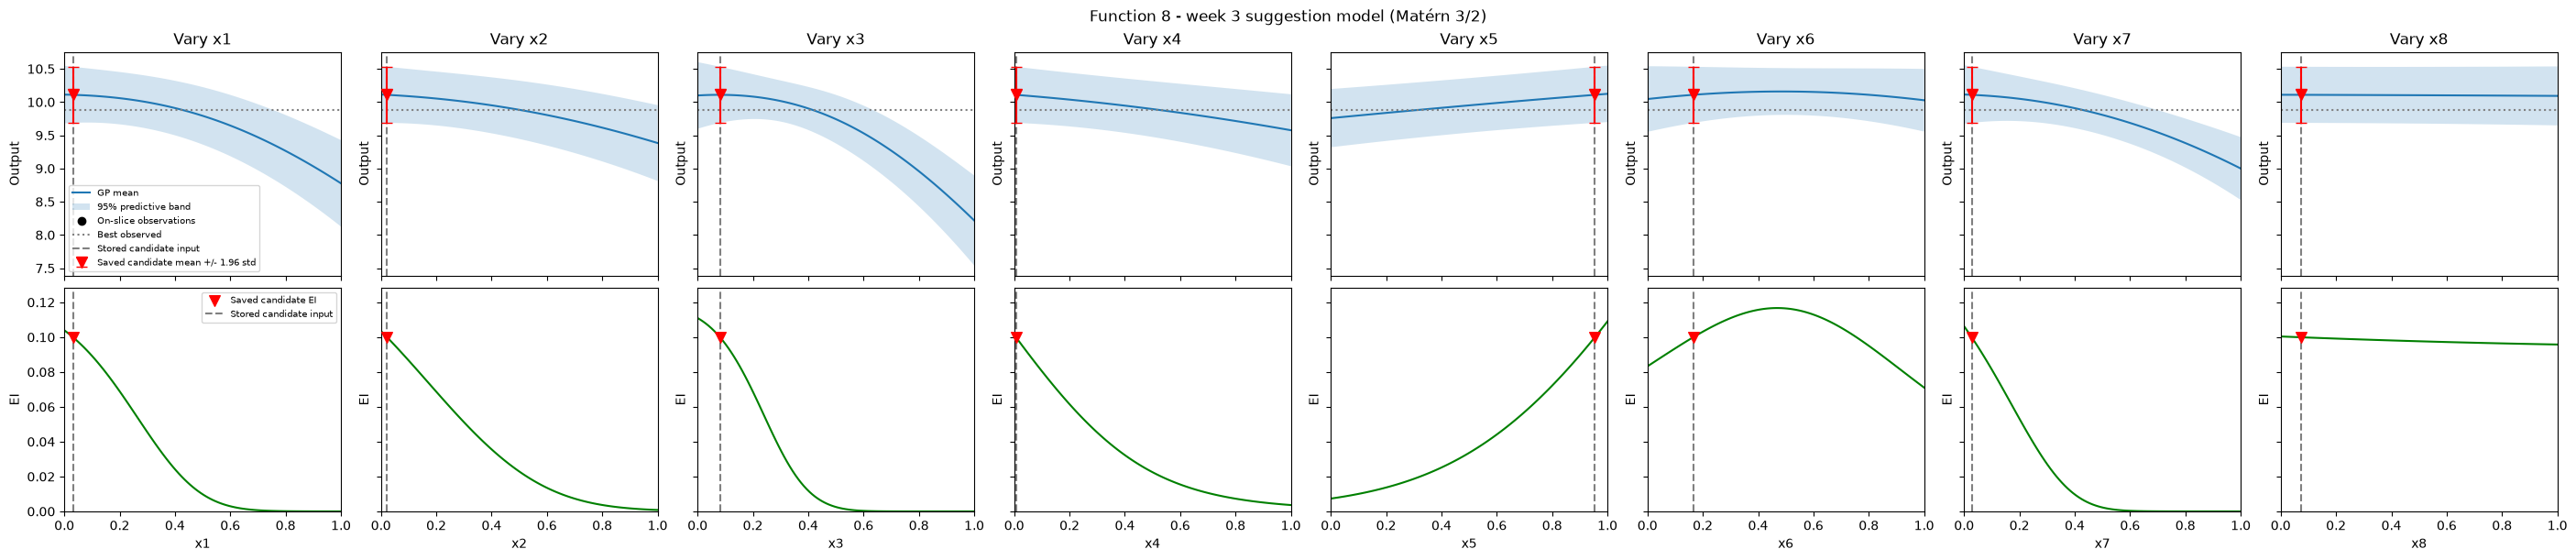

Function 8 - week 3 suggestion model kernel: 7.45**2 * Matern(length_scale=[8.94, 13.3, 6.51, 19.7, 42.9, 13.7, 9.32, 100], nu=1.5) + WhiteKernel(noise_level=1e-08)



In [ ]:
plot_function_ids = tuple(FUNCTION_SPECS)
N_CANDIDATES = CONFIG["candidates"]

for function_id in plot_function_ids:
    observations = TRAINING_OBSERVATIONS[function_id]
    kernel = make_matern_32_kernel(observations.dimension, LENGTH_CAPS[function_id])
    stored = stored_rows.loc[function_id]
    settings = stored.acquisition_settings
    optimizer = BayesianOptimizer(
        observations,
        OptimisationConfig(
            budget=1, candidates=N_CANDIDATES, kernel=kernel,
            xi=settings["xi"], best=settings["best"],
        ),
    )
    plot = plot_gp_2d if observations.dimension == 2 else plot_gp_slices
    figure, _ = plot(
        optimizer,
        n=100,
        candidate=stored.candidate,
        expected_mean=stored.expected_mean,
        expected_std=stored.expected_std,
        expected_ei=stored.acquisition_score,
    )
    figure.suptitle(f"Function {function_id} - week {WEEK + 1} suggestion model (Matérn 3/2)")
    display(figure)
    plt.close(figure)
    print(f"Function {function_id} - week {WEEK + 1} suggestion model kernel: {optimizer._model.kernel_}")
    print()